# Training Neural Networks with Keras

Welcome to the first practical session of the course! In this session, we will learn how to train neural networks with Keras. We will start with a simple example of a feedforward neural network for classification and then we will study the impact of the initialization of the weights on the convergence of the training algorithm.

Keras is a high-level neural network API, built on top of TensorFlow 2.0. It provides a user-friendly interface to build, train and deploy deep learning models. Keras is designed to be modular, fast and easy to use.

Throughout this course, we will focus on using Keras and TensorFlow for building and training neural networks. However, there are other popular deep learning frameworks such as PyTorch, MXNet, CNTK, etc. that you can also use to build and train neural networks.

In order to use our code on Google Colab, we will need to ensure that any required packages are installed. We will use the following packages in this session:

- `tensorflow`: an open-source library for numerical computation and large-scale machine learning.
- `matplotlib`: a plotting library for the Python programming language and its numerical mathematics extension NumPy.
- `numpy`: a library for scientific computing in Python.
- `scikit-learn`: a machine learning library for the Python programming language.
- `pandas`: a library providing high-performance, easy-to-use data structures and data analysis tools for the Python programming language.

Today, we will be working with the famous MNIST dataset. MNIST (Modified National Institute of Standards and Technology) is a database of low resolution images of handwritten digits. The history here is interesting - the dataset was originally created in the 1980s, when researchers from the aforementioned institute collected samples from American Census Bureau employees and high school students. The dataset was then modified in the 1990s (hence the M in MNIST), and has since become a popular benchmark for machine learning algorithms. 

The dataset contains images, each of which is a 28x28 grayscale image of a handwritten digit. The goal is to classify each image into one of the 10 possible classes (0-9).

![MNIST](https://upload.wikimedia.org/wikipedia/commons/2/27/MnistExamples.png)

The Scikit-Learn library provides a convenient function to download and load the MNIST dataset. The following cell will download the dataset. Then we will take a look at the shape of the data.

In [17]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential, initializers
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.utils import to_categorical

try:
    tf.config.set_visible_devices([], 'GPU')
except RuntimeError:
    pass
print('TensorFlow:', tf.__version__)
print('Python can train using the CPU.')
np.random.seed(42)
tf.random.set_seed(42)
digits = load_digits()
print('Images:', digits.images.shape)
print('Flattened data:', digits.data.shape)
print('Labels:', digits.target.shape)

TensorFlow: 2.21.0
Python can train using the CPU.
Images: (1797, 8, 8)
Flattened data: (1797, 64)
Labels: (1797,)


digits.image.shape is 1797, 8, 8 
digit.data.shape is 1797,64

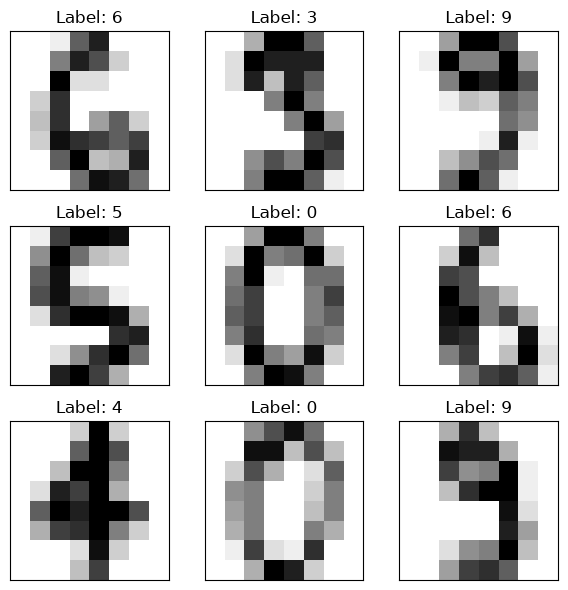

In [18]:
random_indices = np.random.default_rng(42).choice(len(digits.images), 9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for i, ax in enumerate(axes.flat):
    index = random_indices[i]
    ax.imshow(digits.images[index], cmap='gray_r', interpolation='nearest')
    ax.set_title(f'Label: {digits.target[index]}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

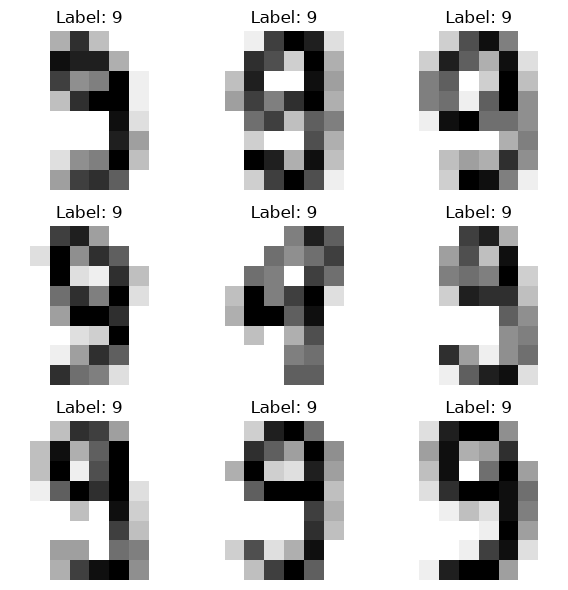

In [19]:
nine_indices = np.flatnonzero(digits.target == 9)
selected_nines = np.random.default_rng(21).choice(nine_indices, 9, replace=False)
fig, axes = plt.subplots(3, 3, figsize=(6, 6))
for index, ax in zip(selected_nines, axes.flat):
    ax.imshow(digits.images[index], cmap='gray_r', interpolation='nearest')
    ax.set_title('Label: 9')
    ax.axis('off')
plt.tight_layout()

In [20]:
X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    digits.data.astype('float32'), digits.target,
    test_size=0.2, random_state=42, stratify=digits.target
)
y_train = to_categorical(y_train_raw, num_classes=10)
y_test = to_categorical(y_test_raw, num_classes=10)
print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print('y_train:', y_train.shape, 'y_test:', y_test.shape)
print('Label example:', y_train_raw[0], 'as one-hot:', y_train[0])

X_train: (1437, 64) X_test: (360, 64)
y_train: (1437, 10) y_test: (360, 10)
Label example: 5 as one-hot: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [22]:
def build_classifier(extra_hidden=False, initialization=None):
    layers = [Input(shape=(64,))]
    for _ in range(3 if extra_hidden else 2):
        kwargs = {'kernel_initializer': initialization} if initialization is not None else {}
        layers.append(Dense(64, activation='relu', **kwargs))
    layers.append(Dense(10, activation='softmax'))
    return Sequential(layers)

model = build_classifier()
model.compile(loss='categorical_crossentropy', optimizer=SGD(), metrics=['accuracy'])
model.summary()
history = model.fit(X_train, y_train, epochs=5, batch_size=32,
                    validation_split=0.2, verbose=1)
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Baseline test loss: {loss:.3f}, accuracy: {accuracy:.1%}')

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,970 (35.04 KB)

 Trainable params: 8,970 (35.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6519 - loss: 1.5600 - val_accuracy: 0.8333 - val_loss: 0.5927
Epoch 2/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8990 - loss: 0.3577 - val_accuracy: 0.8507 - val_loss: 0.4445
Epoch 3/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9269 - loss: 0.2394 - val_accuracy: 0.8646 - val_loss: 0.3691
Epoch 4/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9513 - loss: 0.1819 - val_accuracy: 0.8889 - val_loss: 0.3232
Epoch 5/5
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9669 - loss: 0.1474 - val_accuracy: 0.9062 - val_loss: 0.2860
Baseline test loss: 0.258, accuracy: 91.4%


We can take a look at some random images from the dataset. The following cell will select 9 random images and plot them in a 3x3 grid (meaning that you can rerun the cell to see different images).

Incorrect predictions: 31 / 360


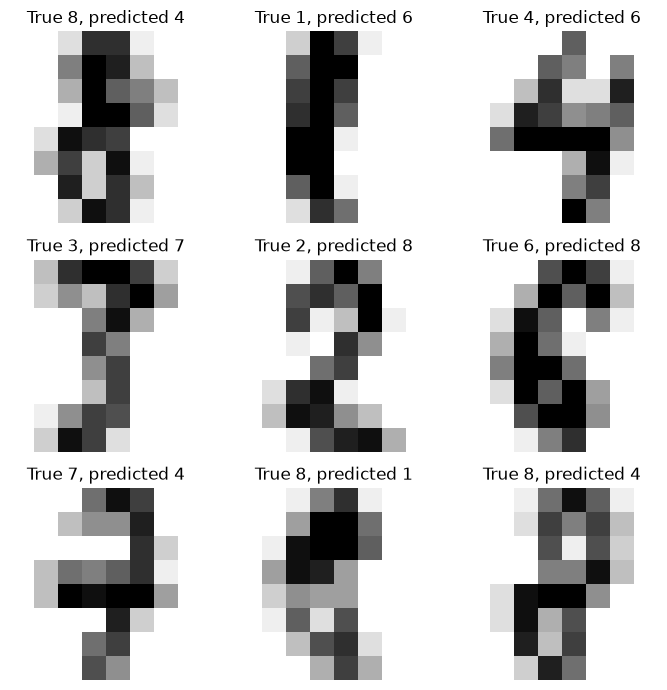

In [23]:
predictions = model.predict(X_test, verbose=0)
predicted_classes = np.argmax(predictions, axis=1)
wrong = np.flatnonzero(predicted_classes != y_test_raw)
print(f'Incorrect predictions: {len(wrong)} / {len(X_test)}')
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for ax, idx in zip(axes.flat, wrong[:9]):
    ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'True {y_test_raw[idx]}, predicted {predicted_classes[idx]}')
    ax.axis('off')
for ax in axes.flat[len(wrong[:9]):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [24]:
optimizer_trials = []

def run_trial(label, opt, extra_hidden=False, epochs=5):
    candidate = build_classifier(extra_hidden=extra_hidden)
    candidate.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    trace = candidate.fit(X_train, y_train, epochs=epochs, batch_size=32,
                          validation_split=0.2, verbose=0)
    test_loss, test_acc = candidate.evaluate(X_test, y_test, verbose=0)
    optimizer_trials.append({'Setting': label, 'Test loss': test_loss,
                              'Test accuracy': test_acc, 'History': trace})
    print(f'{label:27s} | test accuracy {test_acc:.3f} | loss {test_loss:.3f}')
    return candidate

small_lr_model = run_trial('SGD learning rate 0.001', SGD(learning_rate=0.001))
large_lr_model = run_trial('SGD learning rate 0.1', SGD(learning_rate=0.1))
momentum_model = run_trial('SGD momentum 0.9', SGD(learning_rate=0.01, momentum=0.9))
adam_model = run_trial('Adam default', Adam())
extra_model = run_trial('Adam + third hidden layer', Adam(), extra_hidden=True)

SGD learning rate 0.001     | test accuracy 0.675 | loss 1.010
SGD learning rate 0.1       | test accuracy 0.339 | loss 1.680
SGD momentum 0.9            | test accuracy 0.933 | loss 0.215
Adam default                | test accuracy 0.925 | loss 0.205
Adam + third hidden layer   | test accuracy 0.953 | loss 0.166


,Setting,Test loss,Test accuracy
4,Adam + third hidden layer,0.166055,0.952778
2,SGD momentum 0.9,0.215104,0.933333
3,Adam default,0.204806,0.925000
0,SGD learning rate 0.001,1.010327,0.675000
1,SGD learning rate 0.1,1.680059,0.338889


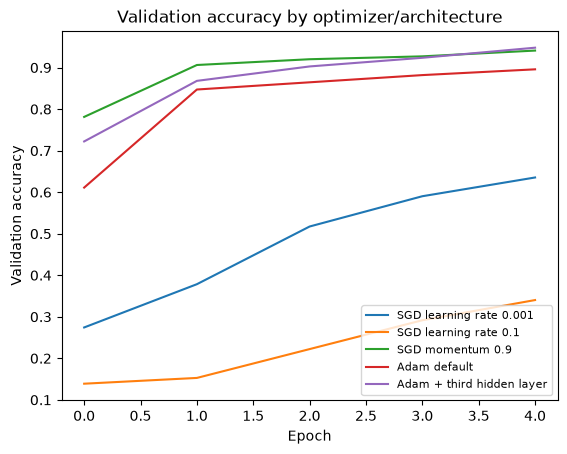

In [25]:
import pandas as pd
summary = pd.DataFrame(optimizer_trials).drop(columns='History')
display(summary.sort_values('Test accuracy', ascending=False))
for trial in optimizer_trials:
    plt.plot(trial['History'].history['val_accuracy'], label=trial['Setting'])
plt.title('Validation accuracy by optimizer/architecture')
plt.xlabel('Epoch')
plt.ylabel('Validation accuracy')
plt.legend(fontsize=8)
plt.show()

Tensor type: <class 'tensorflow.python.framework.ops.EagerTensor'>
Shape: (360, 10)
Probability sums (first five): [0.99999994 1.         1.         1.         1.0000001 ]


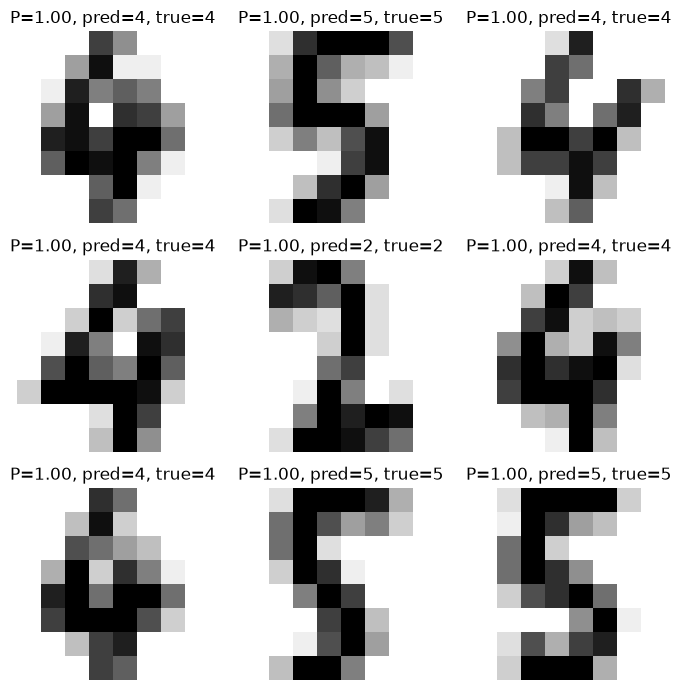

In [26]:
predictions_tf = adam_model(X_test)
print('Tensor type:', type(predictions_tf))
print('Shape:', predictions_tf.shape)
print('Probability sums (first five):', tf.reduce_sum(predictions_tf, axis=1)[:5].numpy())
predicted_labels_tf = tf.argmax(predictions_tf, axis=1)
confidence = tf.reduce_max(predictions_tf, axis=1).numpy()
confident_indices = np.argsort(confidence)[::-1][:9]
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for idx, ax in zip(confident_indices, axes.flat):
    ax.imshow(X_test[idx].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'P={confidence[idx]:.2f}, pred={predicted_labels_tf[idx].numpy()}, true={y_test_raw[idx]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [27]:
def build_initialization_model(scale):
    def new_init():
        if scale == 'zeros':
            return tf.keras.initializers.Zeros()
        return tf.keras.initializers.TruncatedNormal(stddev=float(scale))
    return Sequential([
        Input(shape=(64,)),
        Dense(64, activation='tanh', kernel_initializer=new_init()),
        Dense(64, activation='tanh', kernel_initializer=new_init()),
        Dense(10, activation='softmax', kernel_initializer=new_init()),
    ])

initialization_results = []
for label, scale in [('tiny 0.001', 0.001), ('large 1', 1.0),
                     ('very large 10', 10.0), ('zero weights', 'zeros')]:
    for opt_label in ('SGD', 'momentum', 'Adam'):
        candidate = build_initialization_model(scale)
        optimizer = (SGD(learning_rate=0.1) if opt_label == 'SGD' else
                     SGD(learning_rate=0.1, momentum=0.9) if opt_label == 'momentum'
                     else Adam(learning_rate=0.001))
        candidate.compile(optimizer=optimizer,
                          loss='categorical_crossentropy', metrics=['accuracy'])
        candidate.fit(X_train, y_train, epochs=3, batch_size=32, verbose=0)
        test_loss, test_acc = candidate.evaluate(X_test, y_test, verbose=0)
        initialization_results.append({'Initialization': label, 'Optimizer': opt_label,
                                       'Test loss': test_loss, 'Test accuracy': test_acc})
        print(label, opt_label, f'accuracy={test_acc:.3f}')
display(pd.DataFrame(initialization_results).pivot(index='Initialization',
               columns='Optimizer', values='Test accuracy'))

tiny 0.001 SGD accuracy=0.103
tiny 0.001 momentum accuracy=0.522
tiny 0.001 Adam accuracy=0.764
large 1 SGD accuracy=0.564
large 1 momentum accuracy=0.111
large 1 Adam accuracy=0.333
very large 10 SGD accuracy=0.172
very large 10 momentum accuracy=0.144
very large 10 Adam accuracy=0.069
zero weights SGD accuracy=0.103
zero weights momentum accuracy=0.100
zero weights Adam accuracy=0.100


Optimizer,Adam,SGD,momentum
Initialization,,,
large 1,0.333333,0.563889,0.111111
tiny 0.001,0.763889,0.102778,0.522222
very large 10,0.069444,0.172222,0.144444
zero weights,0.100000,0.102778,0.100000
